# Articial Intelligence and Machine Learning - Coursework 1 - 1st diet
## Modified Chinese-Medicine-163 image dataset
# Student Name: PEACEOJEHANON
# Student Email: pojeha300@caledonian.ac.uk

I confirm that the material contained within the submitted coursework is all my own work unless otherwise stated below.

---

## 1. Introduction and problem definition
### 1.1 Introduction
This report focuses on refining a Convolutional Neural Network (CNN) to classify images of 11 different types of Chinese medicinal herbs. The dataset contains approximately 17,325 images, with about 1,575 images for each herb type. The images are organized into folders, each corresponding to a specific herb.
The dataset, available in a file named ChineseHerbs.zip, presents several challenges, including:
* Variations in image quality (such as blurry images, watermarks, and complex backgrounds).
* Possible class imbalance that could affect model training and performance.
* The necessity for preprocessing and data augmentation to prepare the dataset for effective training.
With these challenges in mind, the main objective is to develop an image classifier using CNNs that can accurately sort these images into the 11 herb categories while effectively extracting meaningful features and addressing any noise and variability.

### 1.2 Problem Definition
The overall goal of this report is to build a CNN-based image classifier that can accurately identify 11 types of Chinese medicinal herbs and offers accurate and robust classification.
The report/project is divdided into the two tages below:
1. **Baseline Model**: We will create a simple CNN that  establishs the initial performance of the classification system.
2. **Enhanced Model**: Here we will created a more enhanced model to improve the baseline model architechture by implementing techniques such as data augmentation and model ehancement architecture.

### Module Imports
Before working with the data one needs to import all relevant Python modules. It is good practice to do that in a single Jupyter Notebook cell at the top of your code, rather than spread throughout the whole file.

**TASK**: Modify your conda environment so that the modules below all have been installed.

In [2]:
# Importing all necessary libraries
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import os
import numpy as np


## 2. Data loading and preparation
### 2.1 Data Loading and Ingestion
In this section, we will be loading the dataset from its folder structure into the environment, ensuring that label associations are maintained by making use of the TensorFlow’s ImageDataGenerator to efficiently load and preprocess the images directly

In [3]:
# Path to your dataset directory (modified)
my_CH_dir = 'C:/Users/fdl_glasgow/Music/ChineseHerbs/ChineseHerbs'

In [4]:
# List the categories of herbs
categories = os.listdir(my_CH_dir)
print(f"Total categories: {len(categories)}")
print("Categories:", categories)

Total categories: 11
Categories: ['cordyceps', 'cornus_fruit', 'dried_ginger', 'dried_mulberry', 'ginseng', 'hawthorn', 'honeysuckle_flower', 'lily_bulb', 'oyster_shell', 'schisandra_berry', 'smoke_plum']


In [5]:
# Count number of images per category
category_counts = {}
for category in categories:
    category_path = os.path.join(my_CH_dir, category)
    category_counts[category] = len(os.listdir(category_path))

for category, count in category_counts.items():
    print(f"{category}: {count} images")

cordyceps: 1564 images
cornus_fruit: 1562 images
dried_ginger: 1566 images
dried_mulberry: 1566 images
ginseng: 1741 images
hawthorn: 1559 images
honeysuckle_flower: 1554 images
lily_bulb: 1565 images
oyster_shell: 1564 images
schisandra_berry: 1568 images
smoke_plum: 1557 images


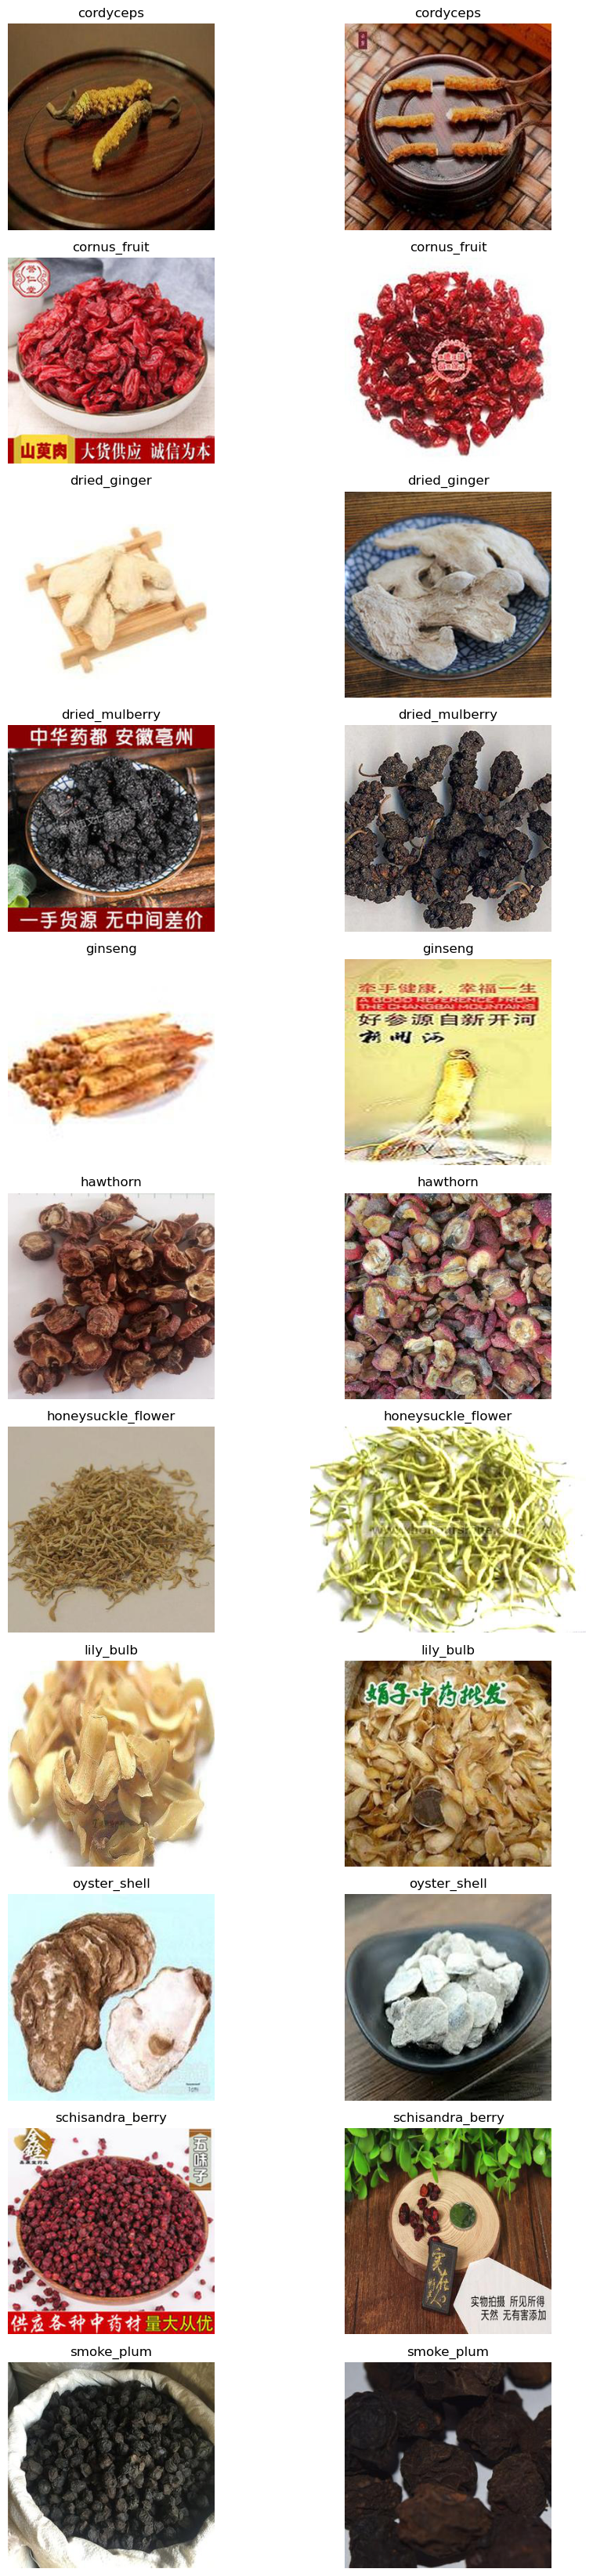

In [7]:
# Displaying sample images from each category
def display_sample_images(my_CH_dir, categories):
    fig, axes = plt.subplots(len(categories), 2, figsize=(10, len(categories) * 3))
    for i, category in enumerate(categories):
        category_path = os.path.join(my_CH_dir, category)
        sample_images = os.listdir(category_path)[:2]
        for j, img_name in enumerate(sample_images):
            img_path = os.path.join(category_path, img_name)
            img = plt.imread(img_path)
            axes[i, j].imshow(img)
            axes[i, j].set_title(category)
            axes[i, j].axis("off")
    plt.tight_layout()
    plt.show()

display_sample_images(my_CH_dir, categories)

The dataset as seen above consists of approximately 17,325 images, clearly categorized into 11 distinct types of Chinese medicinal herbs. It utilizes a folder-based structure, with each category represented by a dedicated subfolder within the main 'ChineseHerbs' directory. Each subfolder contains image files that unequivocally belong to their respective category, organized according to the name of their parent folder.

The following are the 11 categories along with their respective image counts:

- Hawthorn: 1,559 images  
- Schisandra Berry: 1,568 images  
- Honeysuckle Flower: 1,554 images  
- Oyster Shell: 1,564 images  
- Ginseng: 1,741 images  
- Dried Ginger: 1,566 images  
- Cornus Fruit: 1,562 images  
- Smoke Plum: 1,557 images  
- Dried Mulberry: 1,566 images  
- Lily Bulb: 1,565 images  
- Cordyceps: 1,564 images

The images are in JPEG format and display vibrant colors. They use three color channels: red, green, and blue (RGB). You can see these features clearly in the sample images shown above, which highlight the qualities of each category.

### 2.2 Data Preparation
In this section, we will meticulously prepare the dataset to resolve inconsistencies in image sizes and formats. By normalizing pixel values, we will achieve faster and more stable model convergence, while systematically splitting the dataset into targeted subsets for training, validation, and testing. This comprehensive approach ensures a dataset that is not only well-structured but also ready for efficient training of a Convolutional Neural Network (CNN) model. Furthermore, we will employ data augmentation techniques to significantly enhance the diversity of the training set, thereby empowering the CNN model to generalize more effectively to unseen data.

#### 2.2.1 Images Preprocessing
This step in preparing the dataset ensures that the image size and format are standardized, and normalize the pixel values.

In [8]:
# Using ImageDataGenerator for data preparation
data_gen = ImageDataGenerator(rescale=1./255, validation_split=0.2) # Adjust pixel values to range from 0 to 1. Set aside 20% of the data for validation.
training_my_CH_data = data_gen.flow_from_directory( #Create data generators for training and validation.
    my_CH_dir,
    target_size=(150, 150),  # Resize all images to 150x150 pixels
    batch_size=32,  # Number of images in each batch
    class_mode='categorical',  # Convert labels into one-hot encoded format.
    subset='training'  # Use 80% of the data for training.
)

validation_my_CH_data = data_gen.flow_from_directory(
    my_CH_dir,
    target_size=(150, 150),  # Consistent resizing of the images
    batch_size=32,# Number of images in each batch
    class_mode='categorical',# Convert labels into one-hot encoded format
    subset='validation'  # Use 20% of the data for validation
)


Found 13898 images belonging to 11 classes.
Found 3468 images belonging to 11 classes.


Now that we have prepared the dataset, we can confirm that it has been split into training and validation sets using the 80/20 ratio.
The number of training images equals 13,898 while the nmber of validation images equals 3468 , all belonging to the 11 classes/categories of images.

Now , lets look at a sample of the training and validation data

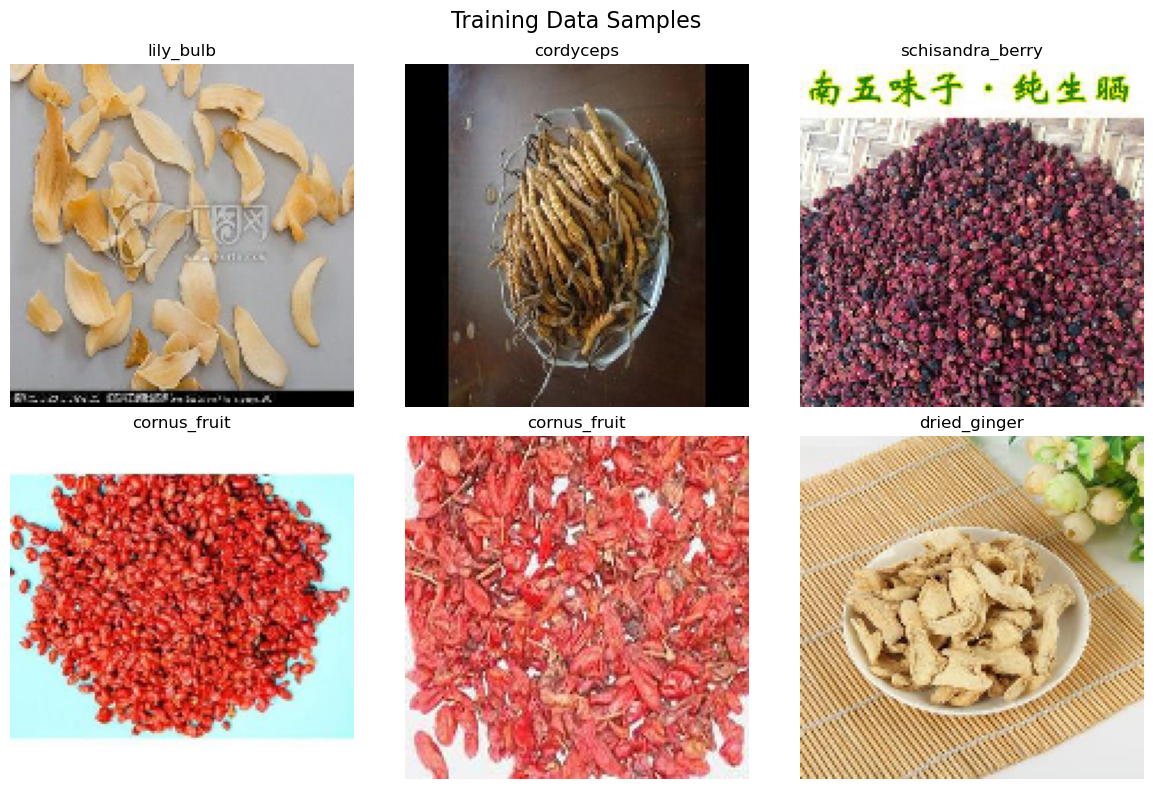

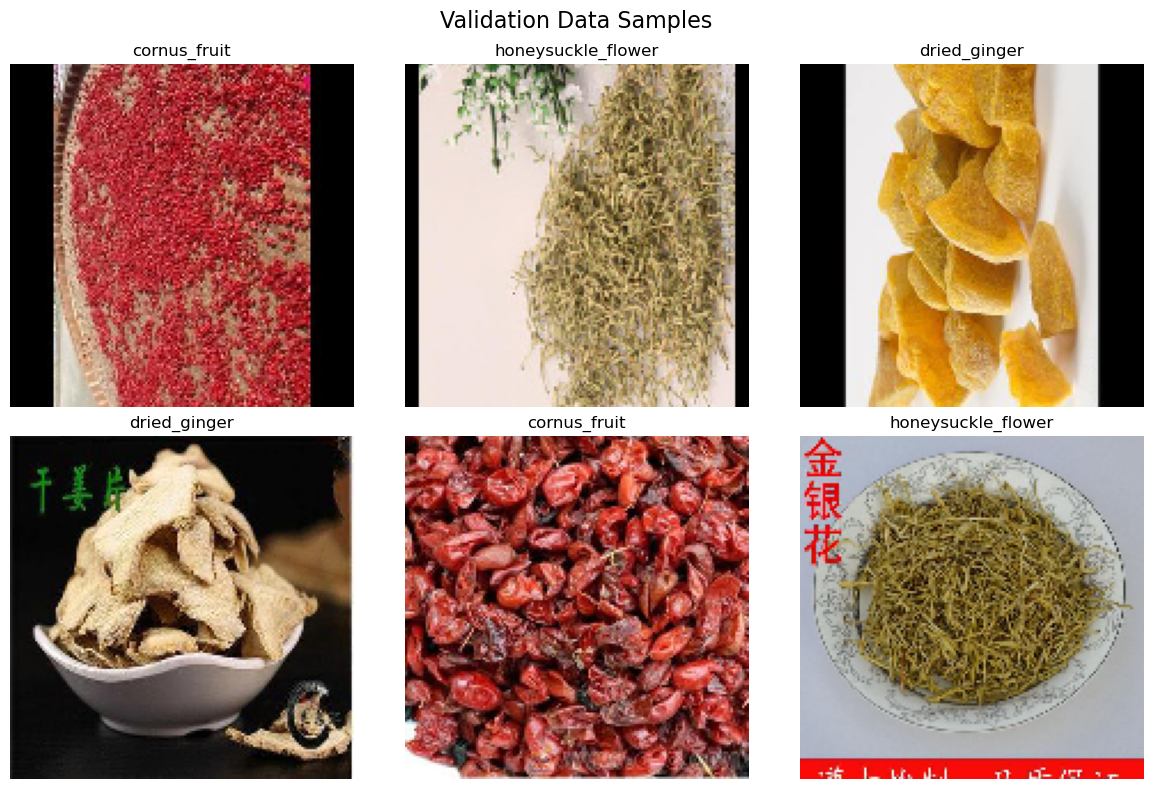

In [11]:
# Get a batch of training data
train_images, train_labels = next(training_my_CH_data)

# Get a batch of validation data
val_images, val_labels = next(validation_my_CH_data)

# Define a function to display images
def display_sample_images(images, labels, class_names, title, num_samples=6):
    plt.figure(figsize=(12, 8))
    for i in range(num_samples):
        plt.subplot(2, num_samples // 2, i + 1)
        plt.imshow(images[i])  # Display image
        label_index = labels[i].argmax()  # Get class index from one-hot encoding
        plt.title(class_names[label_index])  # Display class name
        plt.axis('off')
    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

# Class names from the data generator
class_names = list(training_my_CH_data.class_indices.keys())

# Display training samples
display_sample_images(train_images, train_labels, class_names, "Training Data Samples")

# Display validation samples
display_sample_images(val_images, val_labels, class_names, "Validation Data Samples")

#### 2.2.2 Data Augumentation
Data augmentation can be seen as a technique that artificially enlarges the training dataset by applying a variety of transformations, including rotation, flipping, zooming, and shifting.

While it may be optional generally, it is very vital for the dataset in question as it will  enhance the model's ability  to generalize.
Based on this, we will be simulating various conditions using specific augumentation techniques such as rotation, width shifting, height shifting, shearing, zooming, and horizontal flipping by utilizing the ImageDataGenerator class to apply various transformations to the images in our dataset as shown below

In [16]:
#Generating data to be augumented
datagen_augmented = ImageDataGenerator(
    rescale=1./255,          # Normalize pixel values
    rotation_range=40,       # Rotate images by up to 45 degrees
    width_shift_range=0.2,  # Shift images horizontally by 20% of their width
    height_shift_range=0.2, # Shift images vertically by 20% of their height
    shear_range=0.2,         # Shear images by up to 20%
    zoom_range=0.3,          # Zoom images by up to 30%
    horizontal_flip=True,    # Randomly flip images horizontally
    fill_mode='nearest',     # Fill in pixels after transformations
    validation_split=0.2     # 20% of data for validation
)
# Augmenting generated training Data
aug_training_my_CH_data = datagen_augmented.flow_from_directory(
    my_CH_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

Found 13898 images belonging to 11 classes.


Lets look at a sample of the augumented training data

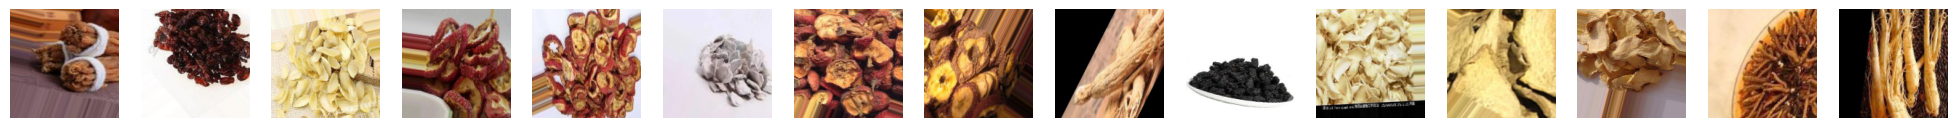

In [18]:
# Function to display a sample of augmented images
def display_augmented_images(generator, num_images):
    # Get a batch of images and labels
    images, labels = next(generator)

    # Plot the augumented images
    fig, axes = plt.subplots(1, num_images, figsize=(25, 5))
    for i in range(num_images):
        axes[i].imshow(images[i])
        axes[i].axis('off')
    plt.show()

# Display a sample of 10 augmented training images
display_augmented_images(aug_training_my_CH_data, 15)

By employing data augmentation techniques as shown above, we have created a more robust dataset by generating a variety of diverse examples for our model to effectively recognize and differentiate between the various herbs.

# TASK 1: Develop a Baseline CNN Model
Developing a Baseline CNN Model entails the creation of a straightforward yet effective Convolutional Neural Network (CNN) that balances simplicity with efficacy. This approach ensures that the model can successfully learn to differentiate between various types of herbs based on their visual characteristics.
In this section, we will examine different configurations of convolutional layers, pooling layers, and activation functions, all while considering techniques such as data augmentation to enhance the model's robustness.

## 3. Define a basic CNN model
In this part, we will use convolutional layers, pooling layers, and fully connected (Dense) layers to create a simple CNN model architecture. This approach is effective for image classification tasks and is relatively easy to implement and understand making it effective for extracting features from images and making predictions.

**Step 1** **involves defining the baseline CNN model** as seen below

In [38]:
#creating the baseline CNN model
my_initial_CNN_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),# Input layer
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),# First convolutional layer
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),# Second convolutional layer
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.GlobalAveragePooling2D(),# Global Average Pooling layer
    tf.keras.layers.Dense(128, activation='relu'),# Fully connected (Dense) layer
    tf.keras.layers.Dense(11, activation='softmax'), # Output layer with softmax activation for multi-class classification
    tf.keras.layers.Flatten()
])
# Print the model summary
my_initial_CNN_model.summary()



Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_5 (Conv2D)           (None, 62, 62, 32)        896       
                                                                 
 max_pooling2d_4 (MaxPooling  (None, 31, 31, 32)       0         
 2D)                                                             
                                                                 
 conv2d_6 (Conv2D)           (None, 29, 29, 64)        18496     
                                                                 
 max_pooling2d_5 (MaxPooling  (None, 14, 14, 64)       0         
 2D)                                                             
                                                                 
 global_average_pooling2d_2   (None, 64)               0         
 (GlobalAveragePooling2D)                                        
                                                      

**STEP 2 involves choossing a loss function**

To successfully perform multi-class classification, we will utilize the ***categorical_crossentropy loss function*** which is appropriate because our image labels are one-hot encoded, and this function effectively measures the disparity between the true label distribution and the predicted label distribution.


In [39]:
# Compile the model
my_initial_CNN_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

**STEP 3 involves training the baseline model**

We will train the model using the training data( that has not yet been augumented) and assess its performance with the validation data. This approach enables the model to learn how to classify images accurately and will also further enhance the model's classification capabilities in the evaluation phase.

In [43]:
# Training the baseline model
history = my_initial_CNN_model.fit(
    training_my_CH_data,
    steps_per_epoch=training_my_CH_data.samples // training_my_CH_data.batch_size,
    epochs=15,
    validation_data=validation_my_CH_data,
    validation_steps=validation_my_CH_data.samples // validation_my_CH_data.batch_size,
    verbose=1
)

Epoch 1/15
434/434 [==============================] - 171s 395ms/step - loss: 1.2709 - accuracy: 0.5228 - val_loss: 1.4771 - val_accuracy: 0.4521
Epoch 2/15
434/434 [==============================] - 168s 386ms/step - loss: 1.2238 - accuracy: 0.5422 - val_loss: 1.3490 - val_accuracy: 0.4985
Epoch 3/15
434/434 [==============================] - 170s 392ms/step - loss: 1.1649 - accuracy: 0.5599 - val_loss: 1.3275 - val_accuracy: 0.5050
Epoch 4/15
434/434 [==============================] - 167s 385ms/step - loss: 1.1208 - accuracy: 0.5783 - val_loss: 1.2490 - val_accuracy: 0.5433
Epoch 5/15
434/434 [==============================] - 172s 397ms/step - loss: 1.0915 - accuracy: 0.5864 - val_loss: 1.2321 - val_accuracy: 0.5358
Epoch 6/15
434/434 [==============================] - 172s 396ms/step - loss: 1.0512 - accuracy: 0.6044 - val_loss: 1.2012 - val_accuracy: 0.5645
Epoch 7/15
434/434 [==============================] - 175s 402ms/step - loss: 1.0134 - accuracy: 0.6159 - val_loss: 1.1604 -

## 4. Model evaluation
Now that we have finished training the baseline model, we can also evaluate its performance using the validation data to help us understand how well the model can manage new data.


In [46]:
# checking model's performance on the validation data
loss, accuracy = my_initial_CNN_model.evaluate(validation_my_CH_data)
print(f"Validation data Loss: {loss:.4f}")
print(f"Validation  data Accuracy: {accuracy * 100:.2f}%")


109/109 [==============================] - 25s 226ms/step - loss: 1.0935 - accuracy: 0.6021
Validation data Loss: 1.0935
Validation  data Accuracy: 60.21%


However, we cannot completely rely on accuracy as it is not the most effective. So we would also be generating a classification report, along with the confusion matrix as they offers valuable insights into the model's performance across each class.

In [47]:
from sklearn.metrics import classification_report, confusion_matrix # add to import line and environment at the begining of report
# Get the true labels and predictions
true_labels = validation_my_CH_data.classes
predictions = my_initial_CNN_model.predict(validation_my_CH_data)
predicted_labels = np.argmax(predictions, axis=1)

# Generate classification report
print(classification_report(true_labels, predicted_labels, target_names=validation_my_CH_data.class_indices.keys()))

# Generate confusion matrix
conf_matrix = confusion_matrix(true_labels, predicted_labels)
print(conf_matrix)




109/109 [==============================] - 25s 226ms/step
                    precision    recall  f1-score   support

         cordyceps       0.08      0.11      0.09       312
      cornus_fruit       0.08      0.06      0.07       312
      dried_ginger       0.10      0.08      0.09       313
    dried_mulberry       0.11      0.08      0.09       313
           ginseng       0.09      0.10      0.09       348
          hawthorn       0.07      0.05      0.06       311
honeysuckle_flower       0.09      0.05      0.07       310
         lily_bulb       0.07      0.10      0.08       313
      oyster_shell       0.10      0.10      0.10       312
  schisandra_berry       0.08      0.11      0.09       313
        smoke_plum       0.07      0.07      0.07       311

          accuracy                           0.08      3468
         macro avg       0.09      0.08      0.08      3468
      weighted avg       0.09      0.08      0.08      3468

[[35 19 22 25 47 19 16 39 32 35 23]
 [3

The classification report and confusion matrix outputs above reveal that the model is underperforming across all classes, with the precision, recall, and F1-score for all classes all at approximately 0.10, indicating that the model struggles to distinguish between them and often resorts to random guessing. The confusion matrix highlights numerous misclassifications, with no class showing a clear pattern of correct predictions. With an overall accuracy of 10%, the model's classification appears ineffective, likely due to insufficient training, overlapping features, or an imbalanced dataset.

# TASK 2: Enhance Model Performance
The current evaluation of our model's performace indicates that the model is struggling to effectively learn the data features and to further enhance performanc we will need to implement other techniques such as Data Augumentation, Hyperparameter Tuning, and Model Architecture Enhancement.

**Data Augumentation**

We have already augumented the training data earlier so we will only be improving the data augumentation done by changing a few of the parameters. This will help us in training the enhanced model in the next section.

In [27]:
#Improved data augumention
datagen_augmented = ImageDataGenerator(
    rescale=1./255,          # still Normalizing pixel values
    rotation_range=45,       # Rotate images by up to 45 degrees
    width_shift_range=0.25,  # Shift images horizontally by 25% of their width
    height_shift_range=0.25, # Shift images vertically by 25% of their height
    shear_range=0.3,         # Shear images by up to 30%
    zoom_range=0.3,          # Zoom images by up to 30%
    horizontal_flip=True,    # Randomly flip images horizontally
    vertical_flip=True,      # Randomly flip images vertically
    fill_mode='nearest',     # Fill in pixels after transformations
    validation_split=0.2     # 20% of data for validation
)
# Augmenting generated training Data
training_my_CH_data = datagen_augmented.flow_from_directory(
    my_CH_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)
# Validation Data (no further augmentation but normalized)
validation_my_CH_data  = datagen_augmented.flow_from_directory(
    my_CH_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical',
    subset='validation'     # Use for validation
)

Found 13898 images belonging to 11 classes.
Found 3468 images belonging to 11 classes.


**Hyperparameter Tuning**
Involves parameter optimization and its necessary for our model and involves adjusting parameters such as learning rate, batch size, and the number of epochs to find the combination that yields the best performance while preventing overfitting and underfitting.This can be done manually, using grid search, or random search methods as shown below

In [34]:
from tensorflow.keras.optimizers import Adam # add to imprted libraries at the begining anf anaconda environment
from tensorflow.keras.callbacks import EarlyStopping # add to imprted libraries at the begining anf anaconda environment
# Adjusting hyperparameters
learning_rate = 0.0005  # Reduced learning rate for smoother convergence
batch_size = 64 # Larger batch size for stable updates
epochs = 20 

# compiling the model function with hyperparametered learning rate
my_initial_CNN_model.compile(optimizer=Adam (learning_rate=learning_rate), loss='categorical_crossentropy', metrics=['accuracy'])

#Implementing early stopping to prevent overfitting and save the best model weights.
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True) # Training with early stopping

# training the model after adjusting hyperparameters
history = my_initial_CNN_model.fit(
    training_my_CH_data,
    steps_per_epoch=training_my_CH_data.samples // batch_size,
    validation_data=validation_my_CH_data,
    validation_steps=validation_my_CH_data.samples // validation_my_CH_data.batch_size,
    epochs=epochs,
    callbacks=[early_stop],  # Stop training early if no improvement
)

Epoch 1/20
217/217 [==============================] - 101s 463ms/step - loss: 0.7900 - accuracy: 0.7028 - val_loss: 1.0069 - val_accuracy: 0.6395
Epoch 2/20
217/217 [==============================] - 101s 465ms/step - loss: 0.7775 - accuracy: 0.7097 - val_loss: 0.9712 - val_accuracy: 0.6583
Epoch 3/20
217/217 [==============================] - 100s 460ms/step - loss: 0.7719 - accuracy: 0.7118 - val_loss: 0.9982 - val_accuracy: 0.6565
Epoch 4/20
217/217 [==============================] - 100s 462ms/step - loss: 0.7502 - accuracy: 0.7134 - val_loss: 0.9582 - val_accuracy: 0.6548
Epoch 5/20
217/217 [==============================] - 103s 475ms/step - loss: 0.7471 - accuracy: 0.7186 - val_loss: 0.9902 - val_accuracy: 0.6534
Epoch 6/20
217/217 [==============================] - 103s 477ms/step - loss: 0.7611 - accuracy: 0.7180 - val_loss: 0.9972 - val_accuracy: 0.6586
Epoch 7/20
217/217 [==============================] - 101s 466ms/step - loss: 0.7496 - accuracy: 0.7220 - val_loss: 0.9738 -

Model Architecture Enhancement

This involves creating an architecture of an enhanced model that is built on the baseline architecture by incorporating key advancements that effectively capture complex data patterns and improve generalization. It includes additional convolutional layers with more filters, allowing for deeper feature extraction. Dropout layers are integrated to reduce overfitting by randomly deactivating neurons during training.
Batch normalization is also applied to stabilize and accelerate the learning process, while global average pooling preserves crucial spatial information.

In [36]:
from tensorflow.keras.regularizers import l2 # add to imprted libraries at the begining anf anaconda environment
# creating AN enhanced CNN model architecture
enhanced_model = tf.keras.Sequential([
    # Input layer
    tf.keras.layers.Input(shape=(150, 150, 3)),

    # First Convolutional Block
    tf.keras.layers.Conv2D(64, (3, 3), kernel_regularizer=l2(0.01), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Dropout(0.2),

    # Second Convolutional Block
    tf.keras.layers.Conv2D(128, (3, 3), kernel_regularizer=l2(0.01), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Dropout(0.3),

    # Third Convolutional Block
    tf.keras.layers.Conv2D(256, (3, 3), kernel_regularizer=l2(0.01), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.4),

    # Fully Connected Layer
    tf.keras.layers.Dense(512, activation='relu', kernel_regularizer=l2(0.01)),
    tf.keras.layers.Dropout(0.5),

    # Output Layer
    tf.keras.layers.Dense(11, activation='softmax')
])

# Compile the enhanced model
enhanced_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Print the model summary
enhanced_model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_2 (Conv2D)           (None, 148, 148, 64)      1792      
                                                                 
 batch_normalization (BatchN  (None, 148, 148, 64)     256       
 ormalization)                                                   
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 74, 74, 64)       0         
 2D)                                                             
                                                                 
 dropout (Dropout)           (None, 74, 74, 64)        0         
                                                                 
 conv2d_3 (Conv2D)           (None, 72, 72, 128)       73856     
                                                                 
 batch_normalization_1 (Batc  (None, 72, 72, 128)     

## 6. **Model evaluation**

Here, we will be enchancing the baseline model by training it with the augmented training data to potentially improve its performance. (and also create and train the enhanced model -VGG16, add justification for picking this mode of enhancement)
 

To effectively evaluate the performance of both the baseline and enhanced models, we will use the following classification metrics:
- **Accuracy** provides a general measure of how well the model is performing.
- **Precision and Recall** are essential for evaluating model performance concerning false positives and false negatives.
-The **F1-Score** balances Precision and Recall, making it particularly useful for datasets with imbalanced classes.
-Lastly, the **Confusion Matrix** provides a detailed overview of a model's performance across all classes, highlighting specific areas where the model may struggle.

However , we first need to define our evaluation function for calculating these metric parameters as shown below

In [44]:
# Train the baseline model with augmented training data and validating with the original validation data
history_augmented = model.fit(
    aug_train_data,
    steps_per_epoch=aug_train_data.samples // aug_train_data.batch_size,
    validation_data=val_data,
    validation_steps=val_data.samples // val_data.batch_size,
    epochs=10
)

Epoch 1/10
434/434 ━━━━━━━━━━━━━━━━━━━━ 1013s 2s/step - accuracy: 0.7610 - loss: 0.6443 - val_accuracy: 0.7462 - val_loss: 0.7169
Epoch 2/10
  1/434 ━━━━━━━━━━━━━━━━━━━━ 3:06 431ms/step - accuracy: 0.9000 - loss: 0.3384

/usr/lib/python3.10/contextlib.py:153: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(typ, value, traceback)


434/434 ━━━━━━━━━━━━━━━━━━━━ 1s 500us/step - accuracy: 0.9000 - loss: 0.3384 - val_accuracy: 0.8333 - val_loss: 0.4828
Epoch 3/10
434/434 ━━━━━━━━━━━━━━━━━━━━ 1031s 2s/step - accuracy: 0.7830 - loss: 0.5843 - val_accuracy: 0.7694 - val_loss: 0.6172
Epoch 4/10
434/434 ━━━━━━━━━━━━━━━━━━━━ 2s 457us/step - accuracy: 0.8750 - loss: 0.5984 - val_accuracy: 0.5833 - val_loss: 1.1681
Epoch 5/10
434/434 ━━━━━━━━━━━━━━━━━━━━ 1008s 2s/step - accuracy: 0.7876 - loss: 0.5556 - val_accuracy: 0.7428 - val_loss: 0.7079
Epoch 6/10
434/434 ━━━━━━━━━━━━━━━━━━━━ 2s 425us/step - accuracy: 0.7500 - loss: 0.5329 - val_accuracy: 0.5000 - val_loss: 1.3508
Epoch 7/10
434/434 ━━━━━━━━━━━━━━━━━━━━ 1073s 2s/step - accuracy: 0.7960 - loss: 0.5357 - val_accuracy: 0.7911 - val_loss: 0.5622
Epoch 8/10
434/434 ━━━━━━━━━━━━━━━━━━━━ 3s 816us/step - accuracy: 0.7500 - loss: 0.4334 - val_accuracy: 0.7500 - val_loss: 0.4667
Epoch 9/10
434/434 ━━━━━━━━━━━━━━━━━━━━ 1039s 2s/step - accuracy: 0.8026 - loss: 0.5133 - val_accurac

In [45]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
# Function to evaluate the model
def evaluate_model(model, generator):
    # Get the true labels and predictions
    true_labels = generator.classes
    predictions = model.predict(generator)
    predicted_labels = np.argmax(predictions, axis=1)

    # Calculate metrics
    accuracy = accuracy_score(true_labels, predicted_labels)
    precision = precision_score(true_labels, predicted_labels, average='weighted')
    recall = recall_score(true_labels, predicted_labels, average='weighted')
    f1 = f1_score(true_labels, predicted_labels, average='weighted')
    conf_matrix = confusion_matrix(true_labels, predicted_labels)

    return accuracy, precision, recall, f1, conf_matrix


In [46]:
# Evaluate the baseline model
baseline_metrics = evaluate_model(model, val_data)
print("Baseline Model Metrics:")
print(f"Accuracy: {baseline_metrics[0]:.4f}")
print(f"Precision: {baseline_metrics[1]:.4f}")
print(f"Recall: {baseline_metrics[2]:.4f}")
print(f"F1-Score: {baseline_metrics[3]:.4f}")
print("Confusion Matrix:")
print(baseline_metrics[4])

# Evaluate the enhanced model
enhanced_metrics = evaluate_model(enhanced_model, val_data)
print("\nEnhanced Model Metrics:")
print(f"Accuracy: {enhanced_metrics[0]:.4f}")
print(f"Precision: {enhanced_metrics[1]:.4f}")
print(f"Recall: {enhanced_metrics[2]:.4f}")
print(f"F1-Score: {enhanced_metrics[3]:.4f}")
print("Confusion Matrix:")
print(enhanced_metrics[4])

109/109 ━━━━━━━━━━━━━━━━━━━━ 98s 896ms/step
Baseline Model Metrics:
Accuracy: 0.0980
Precision: 0.0987
Recall: 0.0980
F1-Score: 0.0969
Confusion Matrix:
[[27 29 15 30 46 27 36 20 21 29 32]
 [33 32 16 31 52 14 34 30 30 13 27]
 [29 35 18 25 57 25 23 21 32 19 29]
 [32 19 16 33 48 15 24 31 41 15 39]
 [23 48 23 25 49 16 22 27 49 20 46]
 [25 32 15 26 48 25 34 28 30 17 31]
 [29 26 14 23 50 28 37 21 28 23 31]
 [29 40 22 34 42 14 32 28 23 21 28]
 [24 42 12 26 43 20 26 31 33 20 35]
 [28 35 18 22 54 26 24 31 27 22 26]
 [37 27 22 25 49 23 24 23 26 19 36]]
109/109 ━━━━━━━━━━━━━━━━━━━━ 101s 924ms/step

Enhanced Model Metrics:
Accuracy: 0.0957
Precision: 0.0992
Recall: 0.0957
F1-Score: 0.0950
Confusion Matrix:
[[33 23 30 28 21 18 34 37 33 18 37]
 [39 33 34 22 16 22 29 35 43 15 24]
 [22 39 27 29 11  8 36 37 46 23 35]
 [19 33 32 25 20 25 38 34 48 13 26]
 [29 36 36 32 26 16 36 31 45 27 34]
 [21 30 41 19 13 23 23 36 49 21 35]
 [19 35 35 24 18 20 27 30 45 19 38]
 [31 31 28 20 12 25 34 36 51 16 29]
 [20 31

## 7. Discussion and conclusion
Your text here

---

This cell goes to the very bottom of your submitted notebok.
You are requried to link the sources and web-links that you have used for various parts of this coursework.

Write them sources used in the following format similar to the first examle in the sources list below :

    - what you have used them for : web-link

Sources:
- Discusses the use of Convolutional Neural Networks (CNNs) for image classification, particularly in the realm of Chinese medicinal herbs : https://link.springer.com/chapter/10.1007/978-3-031-52216-1_4
- Highlights how CNNs are applied in the recognition and retrieval of images related to Chinese herbal medicine : https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0156327
- Offers insights into Scikit-learn, a versatile library for machine learning particularly in model selection : https://scikit-learn.org/stable/model_selection.html
- Explains the use of TensorFlow's ImageDataGenerator for data augmentation and preprocessing : https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator
- Offers guidelines for loading and preparing image data for machine learning : https://www.tensorflow.org/tutorials/load_data/images
- Provides best practices for building and enhancing CNNs : https://machinelearningmastery.com/how-to-develop-a-cnn-from-scratch-for-cifar-10-photo-classification/
- Breaks down the model compilation process in TensorFlow : https://www.tensorflow.org/api_docs/python/tf/keras/Model#compile
- Offers advice on evaluating machine learning models : https://scikit-learn.org/stable/modules/model_evaluation.html
- Suggests best practices for data augmentation in machine learning : https://machinelearningmastery.com/how-to-configure-image-data-augmentation-when-training-deep-learning-neural-networks/
- Explains the concept of hyperparameter tuning in machine learning : https://machinelearningmastery.com/hyperparameter-optimization-with-random-search-and-grid-search/
- Discusses the implementation of early stopping in deep learning : https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping
- Provides recommendations for improving CNN performance : https://www.ejece.org/index.php/ejece/article/view/596/
- Offers an overview of various data augmentation methods and their practical benefits : https://www.ccslearningacademy.com/what-is-data-augmentation